# 05 · Mô hình chi phí, chính sách k = 3 và độ nhạy

**Mục tiêu.** Chuyển chất lượng dự báo thành **giá trị vận hành**: nếu mỗi sáng hỗ trợ 3 tổ theo một chính sách nào đó, nhà máy được lợi bao nhiêu so với không làm gì, so với quy tắc kinh nghiệm B1 và quy tắc B2? Đề yêu cầu đánh giá chi phí của từng loại dự báo sai và đưa ra ước tính tác động định lượng dựa trên giả định rõ ràng.

**Mô hình chi phí.** Mỗi ngày cảnh báo k tổ.
- Cảnh báo **đúng** một tổ sẽ trượt (dương tính thật): hỗ trợ giúp lấy lại một phần r của thiệt hại.
- Cảnh báo **nhầm** một tổ vốn sẽ đạt (dương tính giả): tốn chi phí một lần hỗ trợ C_int mà không thu lại gì.
- **Bỏ sót** một tổ trượt (âm tính giả): mất toàn bộ thiệt hại của tổ đó (chính sách nào cũng chịu, nên không cộng vào chênh lệch giữa các chính sách).

Lợi ích ròng/ngày = r × (thiệt hại của các tổ trượt được cảnh báo đúng) − C_int × (số cảnh báo).

**Các giả định** (đều là giả định, nên có phần độ nhạy ở mục 4):

| Giả định | Giá trị cơ sở | Dải độ nhạy | Ý nghĩa |
|---|---|---|---|
| k | 3 tổ/ngày | 1–8 (chỉ để tham khảo) | Số kỹ thuật viên/IE có thể cử đi mỗi sáng; cố định theo nguồn lực, không chọn theo dữ liệu |
| r | 0,30 | 0,10–0,50 | Tỷ lệ thiệt hại lấy lại được nhờ hỗ trợ |
| C_int | 240 phút chuẩn | 120–480 | Chi phí một lần hỗ trợ, khoảng nửa ca của một kỹ thuật viên |
| Độ dài ca | 480 phút | – | Dùng để quy đổi năng suất ra phút chuẩn |

**Hai lăng kính thiệt hại.**
- **(a) Chi phí lao động (phút chuẩn):** thiệt hại = (định mức − thực tế) × số công nhân × 480. Lăng kính này coi một phút của tổ đông người quan trọng như một phút của tổ ít người.
- **(b) Giao hàng (sản phẩm thiếu):** thiệt hại (a) chia cho `smv`, tức số sản phẩm không làm ra được. C_int được quy đổi tương ứng: 240 / trung vị `smv` của train. Đây là một giả định: coi 240 phút của kỹ thuật viên tương đương 240 phút chuẩn sản xuất.

**Lăng kính (b) là lăng kính chính**, vì finishing là khâu cuối trước khi xuất hàng và tính theo sản phẩm thì thiệt hại của hai bộ phận tương đương nhau. Tuy vậy, mục 3 cho thấy **kết luận đổi chiều nếu dùng lăng kính (a)**; cần đọc kỹ trước khi đưa ra khuyến nghị.

**Dữ liệu dùng để chọn và đánh giá:** dự báo out-of-fold của **khối 2–5 (31 ngày)**. Khối 1 bị bỏ vì chính sách thiệt hại kỳ vọng có hiệu chỉnh cần bộ hiệu chỉnh fit trên các khối đứng trước; để mọi chính sách được so trên cùng các ngày, cả bảng đều dùng khối 2–5. Đây cũng là bộ số liệu dùng trong `RESULTS_SUMMARY.md`. Test chỉ dùng ở mục 5 để kiểm tra.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # chạy được từ notebooks/ hoặc từ gốc repo
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)

from config import DATA_FILE, SEED
import plots as P

import features as F
import splits as S
import evaluate as E
import pipeline as PL
import cost as C
import calibration as CAL

df = F.build_dataset(DATA_FILE)
train, test = S.split_train_test(df)
cv = S.RollingOriginByDate(n_blocks=6)
sel = E.select_models(train, "A", cv)        # khoảng 40 giây
summ = E.summarize_folds(sel["folds"])
main = summ.sort_values("average_precision_mean", ascending=False).model.iloc[0]
setup = C.CostSetup(smv_median=float(train["smv"].median()))

# OOF khối 2-5: cùng các ngày cho mọi chính sách (kể cả bản có hiệu chỉnh)
y = train.set_index("row_id")["miss"]
frame = E.oof_frame(train, sel["oof"])
mask = (frame.fold >= 2).to_numpy()
f25 = frame[mask].reset_index(drop=True)
p25 = {m: v[mask] for m, v in E.align_scores(frame, sel["oof"], "A").items()}
PROBA = ["DecisionTree", "MLP", "Logistic", "RandomForest"]
cal = {m: CAL.calibrate_oof(sel["oof"][sel["oof"].model == m], y) for m in PROBA}
c25 = {m: c.set_index("row_id")["score_cal"].reindex(f25.row_id).to_numpy() for m, c in cal.items()}
focus = list(dict.fromkeys([main, f"{main}_EV", f"{main}_EVcal", "B1", "B2", "B0"]))

print("Mô hình chính:", main, "| C_int(b) =", round(setup.c_int("b"), 2), "sản phẩm/lần |",
      "OOF khối 2-5:", f25.date.nunique(), "ngày,", len(f25), "dòng")
setup.table().round(2)

Mô hình chính: RandomForest | C_int(b) = 15.73 sản phẩm/lần | OOF khối 2-5: 31 ngày, 606 dòng


,lens,lens_label,unit,r_base,c_int_base,smv_median_train,c_int_min,c_int_max
0,a,(a) chi phí lao động (phút chuẩn),phút chuẩn,0.3,240.00,15.26,120.00,480.00
1,b,(b) giao hàng (sản phẩm thiếu),sản phẩm,0.3,15.73,15.26,7.86,31.45


**Nhận xét.**
- Mô hình chính là Random Forest (chọn ở `04_models`). C_int ở lăng kính (b) là 240 / 15,26 ≈ 15,7 sản phẩm cho một lần hỗ trợ, với dải độ nhạy 7,9–31,5.
- Bảng chi phí dùng 31 ngày (606 dòng) của khối 2–5. Các con số ở notebook này trùng với `RESULTS_SUMMARY.md` mục 8.

## 1. Thiệt hại mỗi lần trượt theo hai lăng kính
**Vì sao xem bảng này trước.** Chính sách nào được coi là tốt phụ thuộc vào việc một lần trượt của mỗi bộ phận "đắt" đến đâu. Bảng dưới là trung vị thiệt hại của một lần trượt.

In [2]:
d = pd.DataFrame({"department": df.department, "miss": df.miss, "a_phut_chuan": C.damage(df, "a"), "b_san_pham": C.damage(df, "b")}).query("miss == 1")
d.groupby("department")[["a_phut_chuan", "b_san_pham"]].median().round(0)

,a_phut_chuan,b_san_pham
department,,
finishing,618.0,177.0
sewing,3722.0,143.0


**Nhận xét.**
- **Theo phút chuẩn**, một lần trượt của sewing mất trung vị khoảng 3.700 phút, gấp khoảng 6 lần finishing (khoảng 620 phút), vì tổ sewing đông người hơn nhiều.
- **Theo sản phẩm thiếu**, hai bộ phận gần nhau (finishing khoảng 177, sewing khoảng 143 sản phẩm), vì mỗi sản phẩm của finishing chỉ tốn ít phút chuẩn.
- Hệ quả: ở lăng kính (a), cảnh báo đúng một tổ sewing "đáng" gấp khoảng 6 lần cảnh báo đúng một tổ finishing. Mà mô hình lại hay cảnh báo finishing (vì finishing trượt nhiều), nên ở lăng kính (a) mô hình bất lợi. Đây là gốc của kết quả bất lợi ở mục 3.

## 2. Chọn chính sách k = 3 trên OOF (khối 2–5)
**Các chính sách được so:**
- `RandomForest`: cảnh báo 3 tổ có **điểm rủi ro** (xác suất chưa hiệu chỉnh) cao nhất.
- `RandomForest_EV`: cảnh báo 3 tổ có **thiệt hại kỳ vọng** cao nhất, tức điểm rủi ro × quy mô mục tiêu biết đầu ca (lăng kính a: `targeted × workers × 480`; b: chia thêm `smv`). Ý tưởng: ưu tiên tổ vừa dễ trượt vừa "lớn".
- `RandomForest_EVcal`: như trên nhưng dùng **xác suất đã hiệu chỉnh** (xem `07_extensions`): điểm rủi ro thô bị `class_weight="balanced"` đẩy lên nên nhân với quy mô có thể lệch.
- B1, B2, B0: baseline.

**Quy tắc chọn, định trước:** chính sách có lợi ích ròng/ngày lớn nhất ở **lăng kính chính (b)**, trên OOF khối 2–5. Khoảng tin cậy 95% của lợi ích ròng/ngày tính bằng bootstrap theo ngày (2.000 lần).

In [3]:
cols = ["lens", "policy", "alerts_per_day", "tp_per_day", "recall_pooled", "precision_pooled",
        "net_per_day", "net_per_day_ci_low", "net_per_day_ci_high"]
rep = {}
for lens in C.LENSES:
    sc = C.policy_scores(f25, p25, lens, PROBA, c25)
    rep[lens] = C.cost_report(f25, sc, lens, setup, focus, "oof_b2_5")
oof_summary = pd.concat([rep[l]["summary"].assign(lens=l) for l in C.LENSES])
cand = oof_summary[(oof_summary.lens == C.PRIMARY_LENS) & oof_summary.policy.isin(focus[:3])]
chosen = cand.sort_values("net_per_day", ascending=False, kind="stable").policy.iloc[0]
print("Chính sách được chọn (lợi ích ròng/ngày lớn nhất ở lăng kính b, OOF khối 2-5):", chosen)
oof_summary[oof_summary.policy.isin(focus)][cols].round(2)

Chính sách được chọn (lợi ích ròng/ngày lớn nhất ở lăng kính b, OOF khối 2-5): RandomForest


,lens,policy,alerts_per_day,tp_per_day,recall_pooled,precision_pooled,net_per_day,net_per_day_ci_low,net_per_day_ci_high
4,a,RandomForest,3.0,1.65,0.29,0.55,119.13,-199.79,462.10
5,a,B0,0.0,0.00,0.00,NaN,0.00,0.00,0.00
6,a,B1,3.0,1.58,0.28,0.53,719.44,144.71,1374.91
7,a,B2,3.0,1.42,0.25,0.47,-401.96,-506.10,-280.81
11,a,RandomForest_EV,3.0,1.13,0.20,0.38,1132.78,559.90,1758.19
15,a,RandomForest_EVcal,3.0,1.23,0.22,0.41,1289.37,668.13,1941.08
4,b,RandomForest,3.0,1.65,0.29,0.55,77.38,44.51,113.39
5,b,B0,0.0,0.00,0.00,NaN,0.00,0.00,0.00
6,b,B1,3.0,1.58,0.28,0.53,66.83,34.00,102.82
7,b,B2,3.0,1.42,0.25,0.47,40.43,11.29,73.68


**Nhận xét.**
- **Lăng kính (b), lăng kính chính:** Random Forest xếp theo điểm rủi ro đạt **77,4 sản phẩm/ngày** [44,5; 113,4], cao nhất trong ba cách xếp hạng (bản thiệt hại kỳ vọng 51,0, bản có hiệu chỉnh 61,9) nên được chọn. Nó cũng cao hơn B1 (66,8) và B2 (40,4) về điểm ước lượng. Trung bình mỗi ngày bắt đúng 1,65 trong 3 tổ được cảnh báo (precision 55%).
- Tuy vậy, khoảng tin cậy của ba cách xếp hạng và của B1 **chồng lên nhau rất nhiều**. Quy tắc chọn theo điểm ước lượng lớn nhất cho ra một lựa chọn, nhưng dữ liệu chưa đủ để nói lựa chọn đó tốt hơn hẳn các phương án khác.
- **Lăng kính (a): kết quả ngược lại, cần nêu thẳng.** Random Forest xếp theo điểm rủi ro chỉ được 119 phút chuẩn/ngày, khoảng tin cậy chứa 0 [−200; 462], trong khi **B1 được 719** [145; 1.375]. Các bản thiệt hại kỳ vọng làm tốt hơn hẳn (1.133 và 1.289), vì chúng ưu tiên tổ đông người. Riêng B2 ("mọi tổ finishing") âm ở lăng kính (a), vì tổ finishing nhỏ.
- Như vậy **chính sách được chọn chỉ tốt nếu nhà máy quan tâm tới số sản phẩm giao hàng**. Nếu nhà máy quan tâm tới chi phí lao động, chính sách đó kém quy tắc "hôm qua trượt".

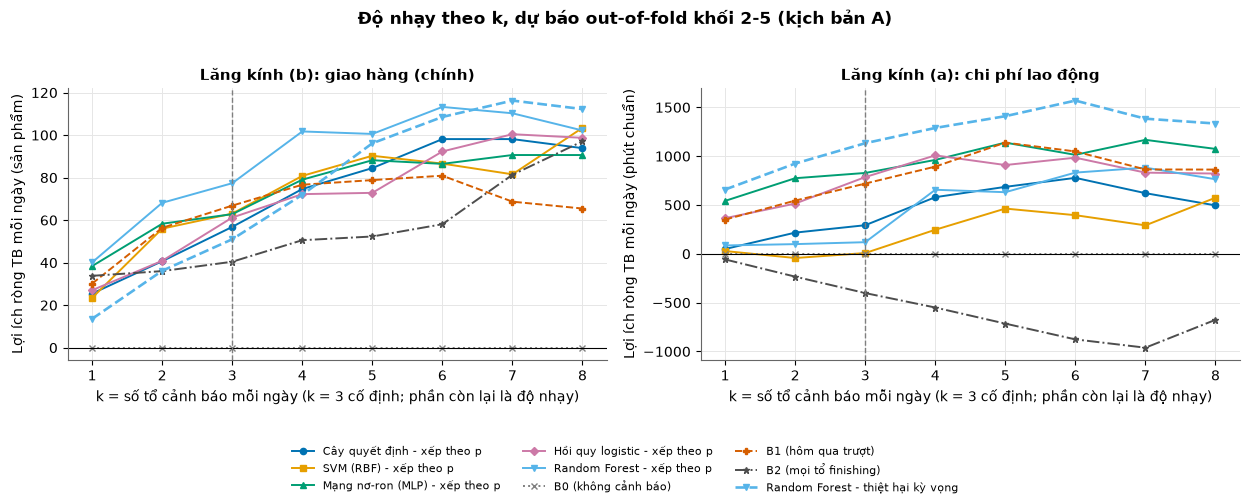

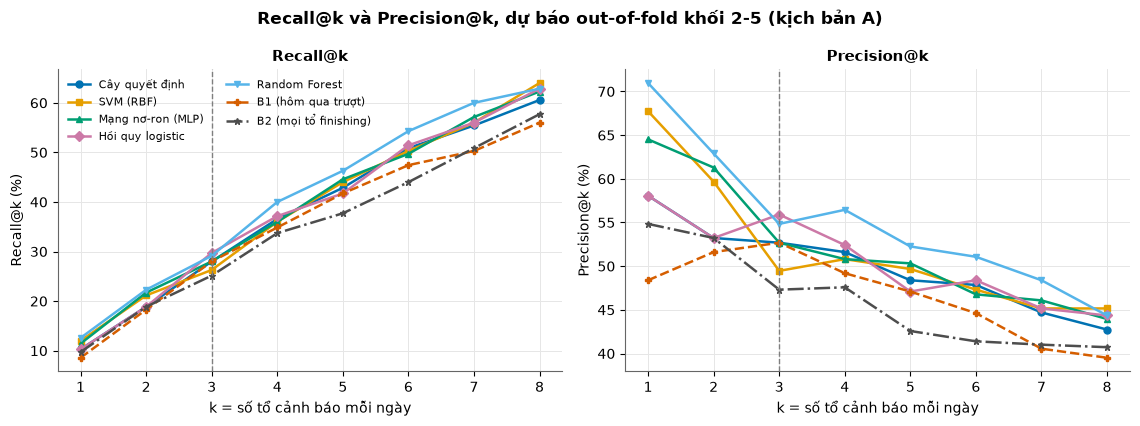

In [4]:
curve = pd.concat([C.policy_curve(f25, C.policy_scores(f25, p25, l, [main]), l, setup).assign(lens=l, source="oof") for l in C.LENSES])
fig = P.plot_net_benefit_vs_k(curve, "oof", C.K_BASE, "Độ nhạy theo k, dự báo out-of-fold khối 2-5 (kịch bản A)"); plt.show()
fig = P.plot_recall_precision_k(curve, "Recall@k và Precision@k, dự báo out-of-fold khối 2-5 (kịch bản A)"); plt.show()

**Nhận xét.**
- **Lăng kính (b), trái:** Random Forest xếp theo điểm rủi ro đứng đầu ở mọi k từ 1 đến 6. Lợi ích ròng tiếp tục tăng tới khoảng k = 6 (khoảng 113 sản phẩm/ngày, so với 77 ở k = 3). Nghĩa là nếu nhà máy có thêm người để hỗ trợ, giá trị còn tăng; k = 3 là giới hạn nguồn lực, không phải điểm tối ưu.
- **Lăng kính (a), phải:** ở k ≤ 3, Random Forest xếp theo điểm rủi ro nằm gần cuối (ở k = 2–3 chỉ trên SVM), dưới B1, MLP, Logistic và cây quyết định. Bản thiệt hại kỳ vọng của Random Forest cao nhất ở mọi k từ 1 đến 8.
- Đường cong theo k chỉ là phân tích độ nhạy: k = 3 được cố định trước theo nguồn lực, không chọn theo đường cong này (chọn k bằng cách lấy đỉnh của một đường cong nhiễu sẽ cho kết quả lạc quan).
- Hình Recall@k và Precision@k: khi k tăng thì bắt được nhiều tổ trượt hơn (recall tăng) nhưng tỷ lệ cảnh báo đúng giảm (precision giảm), đúng như kỳ vọng.

## 3. Hiệu so với B1 và B2 (bootstrap theo ngày, cả hai lăng kính)
**Vì sao cần bảng này.** Hai chính sách được đánh giá trên **cùng các ngày**, nên so chênh lệch theo từng ngày rồi bootstrap chênh lệch đó sẽ chính xác hơn so hai khoảng tin cậy riêng. `p_diff_gt0` là tỷ lệ số lần bootstrap mà chính sách tốt hơn baseline; khoảng tin cậy chứa 0 nghĩa là **chưa có bằng chứng** chính sách hơn baseline.

In [5]:
boot = pd.concat([rep[l]["bootstrap"].assign(lens=l) for l in C.LENSES])
boot[boot.policy.isin(focus)][["lens", "policy", "ref", "diff_mean", "ci_low", "ci_high", "p_diff_gt0", "n_days"]].round(3)

,lens,policy,ref,diff_mean,ci_low,ci_high,p_diff_gt0,n_days
8,a,RandomForest,B1,-600.305,-1177.058,-80.235,0.006,31
9,a,RandomForest,B2,521.095,210.149,851.556,1.000,31
16,a,RandomForest_EV,B1,413.342,-31.692,885.474,0.968,31
17,a,RandomForest_EV,B2,1534.742,939.046,2183.550,1.000,31
24,a,RandomForest_EVcal,B1,569.932,69.942,1082.478,0.988,31
25,a,RandomForest_EVcal,B2,1691.332,1064.674,2373.210,1.000,31
8,b,RandomForest,B1,10.543,-27.091,48.905,0.705,31
9,b,RandomForest,B2,36.943,8.656,66.415,0.994,31
16,b,RandomForest_EV,B1,-15.828,-47.893,16.300,0.166,31
17,b,RandomForest_EV,B2,10.572,-20.707,44.822,0.718,31


**Nhận xét.**
- **Lăng kính (b):** Random Forest hơn **B2** có ý nghĩa (+36,9 [+8,7; +66,4]) nhưng hơn **B1 thì chưa** (+10,5 [−27,1; +48,9]; chỉ 70% số lần bootstrap là dương). Các bản thiệt hại kỳ vọng không hơn B1.
- **Lăng kính (a):** Random Forest xếp theo điểm rủi ro **thua B1 có ý nghĩa thống kê**: −600 phút chuẩn/ngày [−1.177; −80]. Đây là kết quả bất lợi rõ nhất của cả bài. Ngược lại, bản thiệt hại kỳ vọng có hiệu chỉnh hơn B1 có ý nghĩa (+570 [+70; +1.082]).
- Kết luận trung thực: **mô hình chưa chứng minh được là tốt hơn cách quản đốc đang làm** (B1). Ở lăng kính chính thì ngang hoặc nhỉnh hơn nhưng chưa có ý nghĩa thống kê; ở lăng kính lao động thì chính sách được chọn còn kém hơn.

## 4. Độ nhạy: ba kịch bản giả định và hoà vốn (lăng kính b)
**Vì sao.** r và C_int là giả định chưa được nhà máy xác nhận. Ba kịch bản cho thấy kết luận có còn đúng khi giả định xấu hơn hoặc tốt hơn hay không:
- **Thận trọng:** r = 0,10 và C_int gấp đôi;
- **Cơ sở:** r = 0,30 và C_int cơ sở;
- **Lạc quan:** r = 0,50 và C_int một nửa.

Con số theo tháng tính cho 26 ngày làm việc.

In [6]:
rep["b"]["sens_scenarios"][["policy", "cost_scenario", "r", "c_int", "alerts_per_day", "tp_per_day", "saved_per_month", "net_per_month"]].round(1)

,policy,cost_scenario,r,c_int,alerts_per_day,tp_per_day,saved_per_month,net_per_month
0,RandomForest,Thận trọng,0.1,31.5,3.0,1.6,1079.5,-1374.0
1,RandomForest,Cơ sở,0.3,15.7,3.0,1.6,3238.5,2011.8
2,RandomForest,Lạc quan,0.5,7.9,3.0,1.6,5397.6,4784.2
3,RandomForest_EV,Thận trọng,0.1,31.5,3.0,1.2,851.0,-1602.5
4,RandomForest_EV,Cơ sở,0.3,15.7,3.0,1.2,2552.9,1326.2
5,RandomForest_EV,Lạc quan,0.5,7.9,3.0,1.2,4254.8,3641.5
6,RandomForest_EVcal,Thận trọng,0.1,31.5,3.0,1.4,945.0,-1508.5
7,RandomForest_EVcal,Cơ sở,0.3,15.7,3.0,1.4,2835.0,1608.3
8,RandomForest_EVcal,Lạc quan,0.5,7.9,3.0,1.4,4725.0,4111.6
9,B1,Thận trọng,0.1,31.5,3.0,1.6,988.1,-1465.3


**Nhận xét.**
- **Cơ sở:** Random Forest khoảng **+2.012 sản phẩm/tháng**, B1 khoảng +1.738, B2 khoảng +1.051.
- **Lạc quan:** Random Forest khoảng +4.784 sản phẩm/tháng.
- **Thận trọng: mọi chính sách đều âm** (Random Forest khoảng −1.374/tháng). Nếu hỗ trợ chỉ lấy lại được 10% thiệt hại và tốn gấp đôi dự kiến, thì **không làm gì là tốt nhất**.
- Thứ tự giữa Random Forest và B1 giữ nguyên ở cả ba kịch bản, nhưng khoảng cách nhỏ so với độ bất định ở mục 3.

**Hoà vốn.** Lợi ích ròng tuyến tính theo r và C_int: NB = r·S − C_int·A, với S là thiệt hại của các tổ trượt được cảnh báo đúng và A là số cảnh báo. So với *không làm gì* (B0): mức hoà vốn r* = C_int·A/S và C_int* = r·S/A. So với B1 ở cùng k thì A bằng nhau, nên chênh lệch chỉ phụ thuộc S và không có r* dương (bảng để trống).

In [7]:
rep["b"]["break_even"].round(3)

,lens,source,policy,k,ref,delta_S_per_day,delta_alerts_per_day,r_star,c_int_star
0,b,oof_b2_5,RandomForest,3,B0 (không làm gì),415.197,3.0,0.114,41.520
1,b,oof_b2_5,RandomForest,3,B1,35.145,0.0,NaN,NaN
2,b,oof_b2_5,RandomForest,3,B2,123.143,0.0,NaN,NaN
3,b,oof_b2_5,RandomForest_EV,3,B0 (không làm gì),327.294,3.0,0.144,32.729
4,b,oof_b2_5,RandomForest_EV,3,B1,-52.758,0.0,NaN,NaN
5,b,oof_b2_5,RandomForest_EV,3,B2,35.240,0.0,NaN,NaN
6,b,oof_b2_5,RandomForest_EVcal,3,B0 (không làm gì),363.460,3.0,0.130,36.346
7,b,oof_b2_5,RandomForest_EVcal,3,B1,-16.592,0.0,NaN,NaN
8,b,oof_b2_5,RandomForest_EVcal,3,B2,71.406,0.0,NaN,NaN


**Nhận xét.**
- So với không làm gì, Random Forest hoà vốn khi hỗ trợ lấy lại được ít nhất **r* ≈ 11%** thiệt hại (ở C_int cơ sở), hoặc khi một lần hỗ trợ tốn không quá **C_int* ≈ 41,5 sản phẩm** (ở r = 0,30). Mức r* này rất sát kịch bản thận trọng (r = 10%), nên khuyến nghị **phụ thuộc trực tiếp vào hiệu quả thật của việc hỗ trợ**, điều mà dữ liệu không đo được.
- Các bản thiệt hại kỳ vọng cần r* cao hơn (13–14%), tức kém hơn ở lăng kính (b).
- So với B1 và B2, cùng 3 cảnh báo/ngày nên không có ngưỡng hoà vốn: chênh lệch chỉ phụ thuộc lượng thiệt hại bắt được, và luôn tỷ lệ thuận với r.

## 5. Đánh giá trên test
Mỗi mô hình được `fit` lại trên toàn bộ train rồi dự báo 12 ngày test. Bản có hiệu chỉnh dùng bộ hiệu chỉnh fit trên **toàn bộ** điểm OOF của train. Chính sách đã được chốt ở mục 2; test chỉ để kiểm tra, không dùng để chọn lại. Bảng thứ nhất gồm **mọi** mô hình (xếp theo điểm rủi ro) để thấy vị trí của mô hình chính; bảng thứ hai là chênh lệch so với B1, B2.

In [8]:
tp = pd.concat([E.fit_final_and_predict_test(m, "A", sel["best"][m], train, test)[1] for m in PL.MODEL_NAMES], ignore_index=True)
t_scores = E.align_scores(test, tp, "A")
t_cal = {m: CAL.calibrate_test(sel["oof"][sel["oof"].model == m], y, t_scores[m]) for m in PROBA}
trep = {}
for lens in C.LENSES:
    sc = C.policy_scores(test, t_scores, lens, PROBA, t_cal)
    trep[lens] = C.cost_report(test, sc, lens, setup, focus, "test")
test_summary = pd.concat([trep[l]["summary"].assign(lens=l) for l in C.LENSES])
show = list(dict.fromkeys(PL.MODEL_NAMES + focus))
display(test_summary[test_summary.policy.isin(show)][cols].round(2))
tboot = pd.concat([trep[l]["bootstrap"].assign(lens=l) for l in C.LENSES])
tboot[tboot.policy.isin(focus)][["lens", "policy", "ref", "diff_mean", "ci_low", "ci_high", "p_diff_gt0", "n_days"]].round(3)

,lens,policy,alerts_per_day,tp_per_day,recall_pooled,precision_pooled,net_per_day,net_per_day_ci_low,net_per_day_ci_high
0,a,DecisionTree,3.0,2.25,0.40,0.75,-121.33,-321.49,95.71
1,a,SVM_RBF,3.0,1.75,0.31,0.58,-275.62,-458.40,-88.14
2,a,MLP,3.0,1.75,0.31,0.58,-124.36,-324.14,88.89
3,a,Logistic,3.0,1.83,0.32,0.61,111.20,-260.62,615.92
4,a,RandomForest,3.0,2.08,0.37,0.69,-141.12,-330.41,43.05
5,a,B0,0.0,0.00,0.00,NaN,0.00,0.00,0.00
6,a,B1,3.0,1.67,0.29,0.56,-188.98,-406.86,36.60
7,a,B2,3.0,1.92,0.34,0.64,-140.93,-341.28,65.83
11,a,RandomForest_EV,3.0,0.67,0.12,0.22,447.25,-313.39,1273.55
15,a,RandomForest_EVcal,3.0,0.42,0.07,0.14,-221.66,-719.98,531.52


,lens,policy,ref,diff_mean,ci_low,ci_high,p_diff_gt0,n_days
8,a,RandomForest,B1,47.855,-101.153,204.801,0.722,12
9,a,RandomForest,B2,-0.197,-134.710,142.046,0.491,12
16,a,RandomForest_EV,B1,636.231,-185.898,1525.451,0.922,12
17,a,RandomForest_EV,B2,588.179,-273.185,1494.835,0.898,12
24,a,RandomForest_EVcal,B1,-32.683,-614.678,737.623,0.434,12
25,a,RandomForest_EVcal,B2,-80.735,-676.042,717.711,0.386,12
8,b,RandomForest,B1,27.245,-15.341,71.049,0.902,12
9,b,RandomForest,B2,2.453,-30.914,36.092,0.559,12
16,b,RandomForest_EV,B1,-3.857,-41.770,34.153,0.421,12
17,b,RandomForest_EV,B2,-28.649,-67.538,9.666,0.081,12


**Nhận xét (test, 12 ngày).**
- **Lăng kính (b):** Random Forest đạt 131,4 sản phẩm/ngày. Nhưng **B2 "mọi tổ finishing" đạt 129,0, gần như bằng** (chênh +2,5 [−30,9; +36,1]), và **Logistic còn cao hơn** (137,3). Cây quyết định (113,6), MLP (121,0) và B1 (104,2) cũng không kém bao nhiêu. Trên test, một quy tắc không cần học máy làm tốt ngang mô hình chính.
- So với B1, Random Forest hơn +27,2 nhưng khoảng tin cậy chứa 0 [−15,3; +71,0], giống kết quả trên OOF.
- **Lăng kính (a):** gần như mọi chính sách đều **âm** trên test (Random Forest −141, B1 −189, B2 −141). Chỉ Logistic (+111) và bản thiệt hại kỳ vọng của Random Forest (+447) dương, nhưng khoảng tin cậy của cả hai đều chứa 0.
- Test chỉ có 12 ngày và đã được xem trong quá trình phát triển, nên đây là kiểm tra bổ sung, không phải bằng chứng chính.

## 6. Tổng kết

| Câu hỏi | Lăng kính (b), giao hàng | Lăng kính (a), lao động |
|---|---|---|
| Chính sách được chọn (trên OOF) | Top-3 theo điểm rủi ro của Random Forest | (lăng kính phụ, không dùng để chọn) |
| Lợi ích ròng/ngày trên OOF | 77,4 [44,5; 113,4] sản phẩm | 119 [−200; 462] phút chuẩn |
| So với B1 trên OOF | +10,5 [−27,1; +48,9], **chưa có ý nghĩa** | **−600 [−1.177; −80], kém hơn có ý nghĩa** |
| So với B2 trên OOF | +36,9 [+8,7; +66,4], hơn có ý nghĩa | +521, hơn có ý nghĩa |
| Trên test | 131,4; **B2 129,0 gần bằng, Logistic 137,3 cao hơn** | −141; gần như mọi chính sách đều âm |
| Theo tháng (26 ngày, cơ sở) | khoảng +2.000 sản phẩm | – |
| Hoà vốn so với không làm gì | r* ≈ 11% | – |

**Thông điệp cho phần khuyến nghị:** chính sách có giá trị dương so với không làm gì ở lăng kính giao hàng, nếu hỗ trợ lấy lại được hơn khoảng 11% thiệt hại. Nhưng nó **chưa chắc hơn** quy tắc "hôm qua trượt" và **không hơn** quy tắc "mọi tổ finishing" trên test. Ở lăng kính chi phí lao động thì nó **kém hơn** quy tắc kinh nghiệm. Vì vậy hợp lý nhất là đề xuất **thí điểm có so sánh** (xen kẽ ngày dùng mô hình và ngày dùng B1, ghi lại r thật và chi phí thật), không phải triển khai ngay.